# 확률적 경사 하강법

머신러닝 모델은 데이터로부터 학습하여 최적의 예측을 수행하는 것을 목표로 한다.\
이 과정에서 모델의 **가중치(weights)** 와 **편향(bias)** 을 조정하여 예측 오차를 최소화해야 하는데,\
이러한 최적화 과정의 핵심에 **경사 하강법(Gradient Descent)** 이 있다.\
경사 하강법은 손실 함수(loss function)의 기울기(gradient)를 계산하여 손실이 감소하는 방향으로 파라미터를 조금씩 업데이트하는 최적화 알고리즘이다.\
산을 내려갈 때 현재 위치에서 가장 가파른 내리막 방향으로 한 걸음씩 내려가는 것과 유사한 원리로 작동한다.\
그러나 전통적인 경사 하강법은 모든 훈련 데이터를 사용하여 한 번의 가중치 업데이트를 수행하기 때문에, \
데이터셋이 클 경우 다음과 같은 문제가 발생한다:

- 느린 학습 속도: 매 업데이트마다 전체 데이터를 처리해야 하므로 계산 비용이 크다
- 메모리 부족: 대용량 데이터를 한 번에 메모리에 로드하기 어렵다
- 지역 최솟값(local minimum) 문제: 항상 같은 경로로 학습하여 전역 최솟값(global minimum)이 아닌 지역 최솟값에 갇힐 가능성이 있다

이러한 한계를 극복하기 위해 등장한 것이 **확률적 경사 하강법(Stochastic Gradient Descent, SGD)** 이다. \
SGD는 전체 데이터 대신 무작위로 선택된 일부 샘플만을 사용하여 가중치를 업데이트한다. 이를 통해 다음과 같은 장점을 얻을 수 있다:

- 빠른 학습: 적은 데이터로 자주 업데이트하여 빠르게 수렴
- 메모리 효율성: 전체 데이터를 한 번에 로드할 필요 없음
- 지역 최솟값 탈출: 확률적 변동(stochastic noise)이 더 나은 해를 찾는 데 도움
본 문서에서는 확률적 경사 하강법의 작동 원리, 기존 경사 하강법과의 차이점, 그리고 실제 구현 방법에 대해 알아본다.
특히 **에포크(epoch)** 와 **미니배치(mini-batch)** 의 개념을 중심으로, 어떻게 효율적으로 모델을 학습시킬 수 있는지 살펴볼 것이다.

확률적 경사 하강법의 "확률적" 이라는 단어는 '무작위하게', 혹은 '랜덤하게'를 뜻한다.\
다음 "경사"는 언덕이나 산의 기울기를 나타낼 때 쓰는 '경사'와 같은 의미이다.(즉, 기울기를 나타낸다.)\
"하강법"은 내려가는 방법이다.

다시 말해, **확률적 경사 하강법(Stochastic Gradient Descent)** 는 **경사를 따라 내려가는 방법** 을 뜻한다.

산 꼭대기에서 내려오는 경우를 예로 들어, 경사 하강법은 가장 가파른 경사를 따라 가장 빠른 길을 선택한다.\
훈련 세트를 이용해 모델을 훈련하기 때문에 경사 하강법도 훈련 세트를 이용하여 가장 가파른 길을 찾는다.\
확률적 경사 하강법은 경사 하강법과 같은 원리이지만, 훈련 세트를 선택할 때 랜덤한 샘플을 선택한다.

확률적 경사 하강법은 훈련 세트에서 랜덤하게 **선택된 일부 샘플(미니배치)** 을 사용하여 가파른 경사를 조금 내려간다. 다음 훈련 세트에서 랜덤하게 또 다른 **미니배치**를 선택하여 경사를 조금 내려간다. 이러한 방식으로 전체 샘플을 모두 사용할 때까지 계속한다. (때로는 하나의 샘플만을 사용할 수도 있다.)\
이 일련의 과정을 **에포크(epoch)** 라고 부른다.\
경사 하강법에서 훈련 세트를 한 사이클 모두 사용하는 과정이다.\
일반적으로 경사 하강법은 수십, 수백 번 이상 에포크를 수행한다.
> 검증 데이터가 더 나아지지 않거나 overfitting이 시작되는 경우 에포크를 중단한다. loss 또한 에포크에 관여한다.


## 추가 - 신경망 알고리즘에서의 확률적 경사 하강법
확률적 경사 하강법은 신경망 알고리즘에서도 이용한다.\
신경망은 일반적으로 방대한 데이터를 사용하기 때문에 한 번에 모든 데이터를 한꺼번에 사용하기 어렵다. 또한 모델이 매우 복잡하기 때문에 수학적인 방법으로 해석하기 어렵다.

## 손실 함수
**손실 함수(loss function)** 는 특정 문제에서 머신러닝 알고리즘의 예측값과 실제 값의 차이를 수치화하는 함수이다.\
모델이 **얼마나 틀렸는지**를 측정하여 학습 과정에서 이를 최소화하는 것이 목표이다.

확률적 경사 하강법은 각 에포크를 수행하면서 각 에포크의 손실값을 확인하고, 이 손실값이 최소인 모델이 최적의 모델이라 볼 수 있다.\

분류에서 손실은 확실하게 정의할 수 있다.\
분류에서 정의한 정답을 그대로 맞추지 못하는 것으로 정의할 수 있다.\
4개의 이진 분류 샘플을 예시로 들면,
```
예측    정답
1   =   1
1   !=  0
0   =   0
0   !=  1
```
4개의 예측 중 2개만 맞았으므로 정확도는 $\frac{1}{2} = 0.5$이다.\
정확도를 손실 함수로 사용하는 것도 적절해 보이지만, 가능한 정확도와 개수는 정해져 있다.\
예시로 든 데이터 세트에서 가능한 정확도는 $0, 0.25, 0.5, 0.75, 1$의 5가지가 전부이다.

경사 하강법은 손실 함수의 기울기(gradient)를 계산하여 파라미터를 업데이트한다.\
다만, **정확도는 미분이 불가능**하므로 손실 함수로는 사용이 불가능하다.\
또한, 값의 차이가 각 $0.25$로 크므로 값을 조금만 변경해서는 정확도가 변하지 않는다.

손실 함수를 연속적으로 적절히 만드려면 다른 손실 함수를 사용해야 한다.

## 로지스틱 손실 함수(로그 손실(Log Loss))
./04-1.ipynb에서 사용한 로지스틱 회귀 모델의 확률을 이용할 때, 0~1 사이의 어떤 값도 가능하다.\
즉, **연속적이다.**\
이진 분류 문제에서 로지스틱 손실은 실제 레이블($)과 예측 확률($)을 사용하여 다음과 같이 계산된다:

*   실제 레이블이 1일 때 (=1$): 손실 $= -\log(p)$
*   실제 레이블이 0일 때 (=0$): 손실 $= -\log(1-p)$

위에서 사용한 4개의 이진 분류 샘플의 예측 확률이 각각 .9, 0.2, 0.3, 0.8 가정해보자.\
실제 레이블은 순서대로 , 1, 0, 0 하자.\

### 손실 계산 예시:

1.  **첫 번째 샘플**: 실제 레이블 =1$, 예측 확률 =0.9$
    *   손실 $= -\log(0.9) \approx 0.105$
    *   예측이 정확하므로 손실이 작다.

2.  **두 번째 샘플**: 실제 레이블 =1$, 예측 확률 =0.2$
    *   손실 $= -\log(0.2) \approx 1.609$
    *   실제 레이블이 1인데 0.2로 예측하여 예측이 틀렸으므로 손실이 크다.

3.  **세 번째 샘플**: 실제 레이블 =0$, 예측 확률 =0.3$
    *   손실 $= -\log(1-0.3) = -\log(0.7) \approx 0.357$
    *   실제 레이블이 0인데 0.3으로 예측하여 비교적 정확하므로 손실이 작다.

4.  **네 번째 샘플**: 실제 레이블 =0$, 예측 확률 =0.8$
    *   손실 $= -\log(1-0.8) = -\log(0.2) \approx 1.609$
    *   실제 레이블이 0인데 0.8로 예측하여 예측이 틀렸으므로 손실이 크다.

이러한 계산을 통해 예측이 실제 레이블과 멀어질수록 손실 값이 커지는 것을 확인할 수 있다.\\
특히, 예측 확률이 0 또는 1에 가까워질수록 로그 함수 특성상 손실이 무한대로 커지므로 모델이 잘못된 예측에 큰 페널티를 받게 된다.

## 표기법

## 1. 기본 형태

### 단일 샘플의 손실

$$
L(y, p) = -[y \log(p) + (1-y) \log(1-p)]
$$

여기서:
- $y$: 실제 레이블 (0 또는 1)
- $p$: 양성 클래스(1)일 예측 확률
- $1-p$: 음성 클래스(0)일 예측 확률

### 전체 데이터셋의 손실 (평균)

$$
\text{Log Loss} = -\frac{1}{n} \sum_{i=1}^{n} [y_i \log(p_i) + (1-y_i) \log(1-p_i)]
$$

여기서:
- $n$: 샘플 개수
- $y_i$: $i$번째 샘플의 실제 레이블
- $p_i$: $i$번째 샘플의 예측 확률

## 2. 다른 표기법들

### 표기법 1: 시그모이드 함수 명시

$$
\text{Log Loss} = -\frac{1}{n} \sum_{i=1}^{n} [y_i \log(\sigma(z_i)) + (1-y_i) \log(1-\sigma(z_i))]
$$

여기서:
- $z_i = w^T x_i + b$ (로짓)
- $\sigma(z) = \frac{1}{1 + e^{-z}}$ (시그모이드 함수)

### 표기법 2: $\hat{y}$ 사용

$$
\text{Log Loss} = -\frac{1}{n} \sum_{i=1}^{n} [y_i \log(\hat{y}_i) + (1-y_i) \log(1-\hat{y}_i)]
$$

여기서:
- $\hat{y}_i$: 예측 확률 (= $p_i$)

### 표기법 3: 이진 크로스 엔트로피 (Binary Cross-Entropy)

$$
\text{BCE} = -\frac{1}{n} \sum_{i=1}^{n} [y_i \log(p_i) + (1-y_i) \log(1-p_i)]
$$

## 3. 경우별로 나누어 보기

### 실제 레이블이 1일 때 ($y=1$)

$$
L(1, p) = -[1 \times \log(p) + 0 \times \log(1-p)] = -\log(p)
$$

### 실제 레이블이 0일 때 ($y=0$)

$$
L(0, p) = -[0 \times \log(p) + 1 \times \log(1-p)] = -\log(1-p)
$$

정리하면, 양성 클래스(타깃 값은 1)일 때, 손실은 $-log$(예측 확률값)로 계산한다.\
확률이 1에서 멀어져 0에 가까울수록 손실은 큰 양수가 된다.\
음성 클래스(타깃 값이 0)일 때, 손실은 $-log$(1-예측 확률)로 계산한다.\
이 예측 확률이 0에서 멀어져 1에 가까워질수록 손실은 큰 양수가 된다.

> 타깃은 무조건 1로 바뀌어 곱해지므로 생략하였다.

손실 함수를 성공적으로 정의하였다. 이 손실 함수를 **로지스틱 손실 함수(Logistic Loss function)** 또는 **로그 손실(Log Loss)** 라고 부른다.\
또는 **이진 크로스엔트로피 손실 함수(binary cross-entropy loss function)** 라고도 부른다.

> 더 자세한 손실 함수들은 실습 문단 아래에 서술한다.
위의 예시에서는 이진 분류를 예로 들었지만, 다중 분류의 경우는 **크로스엔트로피 손실 함수(corss-entropy loss function)** 를 사용한다.

- 서술한 손실 함수 중 이진 분류에서의 손실 함수: **로지스틱 손실 함수**. **이진 크로스엔트로피 손실 함수**
- 서술한 손실 함수 중 다중 분류에서의 손실 함수: **크로스엔트로피 손실 함수**

손실 함수를 직접 정의하는 경우는 드물다. 모델에 맞는 손실 함수가 개발되어 있기 때문이다. 이진 분류에서는 로지스틱 손실 함수(로그 손실)를 사용하고, 다중 분류에서는 크로스엔트로피 손실 함수를 이용한다.

> 회귀의 경우도 손실 함수를 정의할 수 있다.
> 회귀의 손실 함수로 평균 절댓값 오차(MAE, Mean Absolute Error)를 사용할 수 있다. 타겟에서 예측을 뺀(예측 오차) 절댓값을 모든 샘플에 평균한 값이다.
> 또는 **평균 제곱 오차(mean squared error)** 를 사용한다. 예측 오차를 제곱한 다음 모든 샘플에 평균한 값이다.

# 확률적 경사 하강법을 이용한 분류 모델

`fish_csv_data`를 가져와 `pandas` 데이터프레임을 선언하겠다.

In [1]:
import pandas as pd
fish = pd.read_csv("https://bit.ly/fish_csv_data")
print(fish.head())

  Species  Weight  Length  Diagonal   Height   Width
0   Bream   242.0    25.4      30.0  11.5200  4.0200
1   Bream   290.0    26.3      31.2  12.4800  4.3056
2   Bream   340.0    26.5      31.1  12.3778  4.6961
3   Bream   363.0    29.0      33.5  12.7300  4.4555
4   Bream   430.0    29.0      34.0  12.4440  5.1340


데이터프레임을 선언했다.\
다음, `Species` 결과값 열을 제외한 모든 열을 입력 데이터로 지정하고, 해당 열은 타깃 데이터로 지정한다.

In [2]:
fish_input = fish[['Weight', 'Length', 'Diagonal', 'Height' ,'Width']] # 여러 개의 열 선택: 데이터프레임
fish_target = fish['Species']

print(type(fish_input))
print(type(fish_target))

<class 'pandas.core.frame.DataFrame'>
<class 'pandas.core.series.Series'>


이 데이터를 훈련 세트와 테스트 세트로 나눈다.

In [3]:
from sklearn.model_selection import train_test_split
train_input, test_input, train_target, test_target = train_test_split(fish_input, fish_target, random_state=42)

`StarndardScaler`를 이용해 표준화 전처리한다.

In [4]:
from sklearn.preprocessing import StandardScaler
ss = StandardScaler()
ss.fit(train_input)
train_scaled = ss.transform(train_input)
test_scaled = ss.transform(test_input)

모든 데이터가 준비되었다.\
sklearn에서 확률적 경사 하강법 모델을 제공하는 대표적인 분류용 클래스는 `SGDClassifier`이다.
[sklearn 문서 링크](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.SGDClassifier.html)
> 회귀 문제의 경우는 `SGDRegressor`을 사용한다.

`SGDClassifier` 객체를 만들 때 2개의 기본 매개변수를 지정한다.\
`loss`는 손실 함수를 지정한다. 우리가 사용한 샘플은 `log_loss`(로지스틱 손실 함수(logistic loss function), 로그 손실)를 사용한다.\
`max_iter`는 최대로 수행할 에포크 회수를 지정한다. 10으로 지정하여 전체 훈련 세트를 10번 에포크한다.
> `random_state`는 랜덤으로 하강하는 방식의 시드값을 지정한다.

이후 해당 모델의 정확도 점수를 출력한다.
> 다중 분류의 경우 `loss`를 이진 분류를 위한 손실 함수(여기서 사용한 로그 손실)로 지정하면 클래스마다 각각의 이진 분류 모델을 만든다.\
> 즉, `Bream`은 양성 클래스로 두고 나머지를 모두 음성 클래스로 치환하는 방식이다. 이러한 방식을 OvR(One versus Rest)(하나 vs 나머지)라고 부른다.

In [5]:
from sklearn.linear_model import SGDClassifier

In [6]:
sc = SGDClassifier(loss="log_loss", max_iter=10, random_state=42)
sc.fit(train_scaled, train_target)
print(sc.score(train_scaled, train_target))
print(sc.score(test_scaled, test_target))

0.7815126050420168
0.8


d:\MLDL\.venv\Lib\site-packages\sklearn\linear_model\_stochastic_gradient.py:733: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


테스트 세트와 훈련 세트의 점수가 모두 낮은 과소적합이다.\
지정한 에포크 횟수가 부족한 것으로 보인다.
> `ConvergenceWarning`이 발생하였다. 에포크 반복 횟수가 낮았다는 경고이다.\
> max_iter 횟수를 다 채울 때까지 변화량이 `tol`(허용 오차)보다 크면, 즉 아직 수렴하지 못했는데 반복이 끝나버리면 경고를 띄우는 것이다.

확률적 경사 하강법은 점진적 학습이 가능하다.\
`SGDClassifier` 객체 인스턴스를 다시 만들지 않고 훈련한 모델 `sc`를 그대로 사용할 수 있다.\
모델을 이어서 훈련할 때에는 `partial_fit()` 메서드를 이용한다.\
이 메서드는 호출할 때마다 1 에포크씩 이어서 훈련한다.\
`partial_fit()` 메서드를 호출하고 모델의 점수를 다시 확인해보자.

In [7]:
sc.partial_fit(train_scaled, train_target)
print(sc.score(train_scaled, train_target))
print(sc.score(test_scaled, test_target))

0.8067226890756303
0.825


점수가 높은 편은 아니지만 에포크를 한 번 더 실행하니 점수가 향샹되었다.\
이 모델을 여러 에포크로 훈련해야 한다. 다만, 그 기준이 모호하다.\
기준을 확실히 하기 위해 기준을 알아본다.

## 에포크와 과대/과소적합, 에포크의 기준
SGD를 이용하는 모델은 반복하는 에포크 횟수에 따라 모델의 과소적합이나 과대적합이 발생할 수 있다.\
에포크 횟수가 적으면 모델이 훈련 세트를 덜 학습하여 과소적합(underfitting)이 발생하고,\
에포크 횟수가 적당하면 모델이 훈련 세트를 완전히 학습할 것이다. 훈련 세트에 잘 맞는 모델이 만들어진다.\
때로 이것이 과대적합(overfitting)될 수도 있다.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

epochs = np.arange(1, 101)

# 훈련 세트: 로그 곡선으로 꾸준히 상승
train_scores = 0.5 + 0.12 * np.log(epochs)

# 테스트 세트: 상승 후 하강하는 곡선
peak_epoch = 40
test_scores = (
    0.5
    + 0.12 * np.log(epochs)
    - 0.0008 * (epochs - peak_epoch) ** 2
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(epochs, train_scores, label='Train Set', color='dodgerblue', linewidth=2)
ax.plot(epochs, test_scores,  label='Test Set',  color='tomato',     linewidth=2)

# 과소적합 구간
ax.axvspan(1, 15, alpha=0.12, color='gray')
ax.text(8, 0.97, 'Underfitting', ha='center', fontsize=10, color='gray', fontweight='bold')

# 최적 지점
ax.axvline(x=peak_epoch, color='green', linestyle='--', linewidth=1.8, label=f'Best Epoch ({peak_epoch})')

# 과대적합 구간
ax.axvspan(peak_epoch, 100, alpha=0.08, color='orange')
ax.text(70, 0.97, 'Overfitting', ha='center', fontsize=10, color='darkorange', fontweight='bold')

ax.set_xlabel('Epoch', fontsize=12)
ax.set_ylabel('Accuracy', fontsize=12)
ax.set_title('Underfitting → Optimal → Overfitting over Epochs', fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
ax.set_ylim(0.45, 1.02)
ax.grid(alpha=0.3)
plt.show()

에포크가 진행됨에 따라 훈련 세트의 정확도는 높아지는 과대적합의 모습을 띄지만, 테스트 세트의 점수는 특정 점수에 도달하고 감소한다.\
이 지점이 모델이 과대적합되기 시작하는 곳이다.\
과대적합이 진행되기 전에 에포크를 멈추는 것을 **조기 종료(early stopping)**라고 한다.\
준비한 데이터셋을 기반으로 위와 같은 그래프를 그려보겠다.

`partial_fit()` 메서드를 이용해 반복 에포크 훈련을 진행하고, 이를 위해 `train_target` 함수의 7개의 클래스 종류 목록을 만든다.\
또한, 에포크마다 각 훈련 세트와 테스트 세트의 점수를 기록하기 위해 두 개의 배열을 생성한다.

In [8]:
import numpy as np
sc_graph = SGDClassifier(loss="log_loss", random_state=42)
train_score = []
test_score = []
classes = np.unique(train_target)

300번 에포크 반복을 수행하여 각 훈련마다 훈련 세트와 테스트 세트에 대한 점수를 기록한다.

In [9]:
from sys import stdout
for _ in range(0, 300):
    sc_graph.partial_fit(train_scaled, train_target, classes=classes)
    train_score.append(sc_graph.score(train_scaled, train_target))
    test_score.append(sc_graph.score(test_scaled, test_target))

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
200
201
202
203
204
205
206
207
208
209
210
211
212
213
214
215
216
217
218
219
220
221
222
223
224
225
226
227
228
229
230
231
232
233
234
235
236
237
238
239
240
241
242
243
244
245
246
247
248
249
250
251
252
253
254
255
256
257
258
259
260
261
262
263
264
265
266
267
268
269
270
271
272
273
274
275
276
27

반복 동안 기록한 훈련 세트와 테스트 세트의 점수를 그래프로 그려보면:

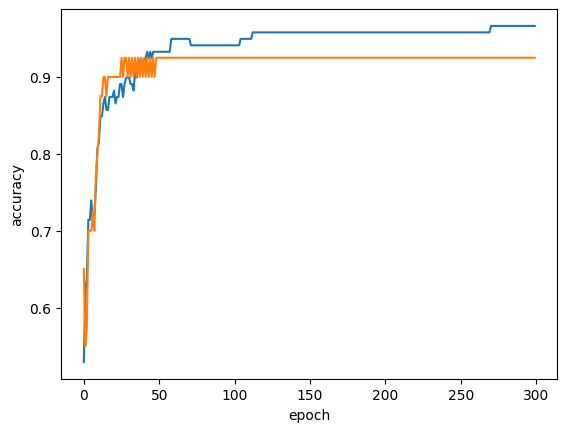

In [10]:
import matplotlib.pyplot as plt
plt.plot(train_score)
plt.plot(test_score)
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.show()

데이터의 크기가 작아 명확히 드러나지는 않지만, 백 번째 에포크 이후에는 훈련 세트와 테스트 세트의 점수가 조금씩 벌어지고 있다.\
또 확실히 에포크 초기에는 과소적합되어 두 세트 모두 점수가 낮다.\
이 모델의 경우 약 100번 정도의 에포크가 적당해 보인다.\
`SGDClassifier`의 `max_iter`를 100으로 지정하고 모델을 다시 훈련한다.

In [12]:
sc = SGDClassifier(loss='log_loss', max_iter=100, tol=None, random_state=42)
sc.fit(train_scaled, train_target)
print(sc.score(train_scaled, train_target))
print(sc.score(test_scaled, test_target))

0.957983193277311
0.925


점수가 크게 향상되었다.
`SGDClassifier`는 일정 에포크 동안 성능이 향상되지 않으면 더 훈련하지 않고 자동으로 에포크를 종료한다.\
방금 선언한 모델에서는 테스트한 에포크 횟수인 100번이 적절한지 확인하기 위해 `tol`(허용 오차값)를 `None`로 지정하여 없애고 지정한 `max_iter`로 무조건 반복되게 하였다.\

최종 점수가 높다. 훈련 세트와 테스트 세트에서의 정확도 점수도 매우 높게 나왔다.

# 확률적 경사 하강법 최종 정리

## 1. 경사 하강법이란?
손실 함수의 기울기(gradient)를 계산하여 손실이 감소하는 방향으로 파라미터를 조금씩 업데이트하는 최적화 알고리즘이다. 산에서 가장 가파른 내리막 방향으로 한 걸음씩 내려가는 것에 비유할 수 있다.

전통적인 경사 하강법은 전체 데이터를 사용하기 때문에 느린 학습 속도, 메모리 부족, 지역 최솟값 문제가 발생한다.

## 2. 확률적 경사 하강법(SGD)이란?
전체 데이터 대신 **무작위로 선택된 일부 샘플(미니배치)** 을 사용하여 가중치를 업데이트하는 방식이다. 전체 샘플을 한 사이클 모두 사용하는 과정을 **에포크(epoch)** 라고 한다.

전통적인 경사 하강법 대비 빠른 학습, 메모리 효율성, 지역 최솟값 탈출의 장점이 있다.

## 3. 손실 함수
모델이 얼마나 틀렸는지를 수치화하는 함수로, 경사 하강법은 이 값을 최소화하는 방향으로 학습한다. 정확도는 미분이 불가능하므로 손실 함수로 사용할 수 없다.

| 문제 유형 | 손실 함수 |
|---|---|
| 이진 분류 | 로지스틱 손실 함수 (로그 손실, 이진 크로스엔트로피) |
| 다중 분류 | 크로스엔트로피 손실 함수 |
| 회귀 | MAE, MSE |

로지스틱 손실 함수 공식:

$$L(y, p) = -[y \log(p) + (1-y) \log(1-p)]$$

## 4. SGDClassifier 실습 흐름

```python
# 1. 데이터 준비 및 전처리
ss = StandardScaler()
train_scaled = ss.fit_transform(train_input)
test_scaled = ss.transform(test_input)

# 2. 모델 생성 및 기본 훈련
sc = SGDClassifier(loss="log_loss", max_iter=10, random_state=42)
sc.fit(train_scaled, train_target)
# → 에포크 부족으로 과소적합, ConvergenceWarning 발생

# 3. partial_fit()으로 점진적 학습
sc.partial_fit(train_scaled, train_target)
# → 호출할 때마다 1에포크씩 이어서 훈련

# 4. 최적 에포크 탐색 (300번 반복)
for _ in range(300):
    sc_graph.partial_fit(train_scaled, train_target, classes=classes)
    train_score.append(sc_graph.score(train_scaled, train_target))
    test_score.append(sc_graph.score(test_scaled, test_target))
# → 약 100번째 에포크 이후 훈련/테스트 점수가 벌어짐

# 5. 최적 에포크로 최종 훈련
sc = SGDClassifier(loss='log_loss', max_iter=100, tol=None, random_state=42)
sc.fit(train_scaled, train_target)
```

## 5. 에포크와 과대/과소적합

- **에포크 부족** → 과소적합: 훈련·테스트 세트 모두 점수 낮음
- **에포크 적당** → 최적 모델
- **에포크 과다** → 과대적합: 훈련 세트 점수는 높고 테스트 세트 점수는 하락

과대적합이 시작되기 전에 학습을 멈추는 것을 **조기 종료(early stopping)** 라고 한다.

## 6. 주요 매개변수 정리

| 매개변수 | 역할 |
|---|---|
| `loss` | 손실 함수 지정 (`log_loss`, `hinge` 등) |
| `max_iter` | 최대 에포크 횟수 |
| `tol` | 수렴 판단 허용 오차 (`None`이면 무조건 `max_iter`까지 반복) |
| `random_state` | 무작위 샘플 선택 시드값 |

# 추가 - 다른 손실 함수
`SGDClassifier`클래스의 `loss` 중 기본값은 `hinge`이다.\
이 손실 함수는 **힌지 손실(hinge loss)**은 **서포트 벡터 머신(support vector machine)**이라 불리는 또 다른 머신러닝 알고리즘을 위한 손실 함수이다.\

서포트 벡터 머신은 데이터를 두 클래스로 분류할 때, **클래스 사이의 경계(결정 경계)를 최대한 넓게** 만드는 것을 목표로 하는 분류 알고리즘이다.

### 핵심 개념

**마진(Margin)** 은 결정 경계와 각 클래스에서 가장 가까운 데이터 포인트 사이의 거리이다. SVM은 이 마진을 최대화하는 경계를 찾는다.

**서포트 벡터(Support Vector)** 는 결정 경계에 가장 가까이 있는 데이터 포인트들로, 경계를 결정하는 데 핵심적인 역할을 한다.

```
 O  O  |  X  X
O   O  |   X  X
  O  ← 마진 → X
       ↑
    결정 경계
```

### SGDClassifier와의 관계
앞서 다룬 `SGDClassifier(loss='hinge')`가 바로 SVM 방식으로 학습하는 것이다. `hinge` 손실 함수가 SVM의 마진을 최대화하는 방식으로 동작한다.

### 장단점
장점으로는 고차원 데이터에서 강하고, 데이터가 적어도 잘 작동하는 편이다. 단점으로는 데이터가 많아지면 학습 속도가 느려지고, 확률값을 직접 출력하지 않는다는 점이 있다.

지금까지 문서에서는 다양한 분류 알고리즘과 회귀 알고리즘을 학습했다.\
다음 문서에서는 신경망 알고리즘을 제외화고 머신러닝에서 뛰어난 성능을 내는 알고리즘인 **트리 알고리즘**을 학습한다.